# Residential Land Price Analysis: India
**Goal:** clean a raw property-listings dataset and analyse residential plot prices by city, state, region and plot size.
**Raw data:** `real_estate_raw.csv` (269,418 listings: apartments, villas, houses and plots).
**Output:** `cleaned_land_data.csv` (46,880 residential plots), used in a Power BI dashboard.
Prices are asking prices in INR. Area is in sq ft.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
raw_data_csv = pd.read_csv("real_estate_raw.csv")

In [3]:
type(raw_data_csv)

pandas.core.frame.DataFrame

In [4]:
raw_data_csv

,plot_type,city,price,Unit,Rupee_per_area,Area,state
0,Residential Plot,Visakhapatnam,90 L,L,"1,000 / sq ft",9000,andhra pradesh
1,Residential Plot,Anantapuram,90 L,L,"1,000 / sq ft",9000,andhra pradesh
2,Residential Plot,Vizianagaram,78.66 L,L,"1,000 / sq ft",7866,andhra pradesh
3,Residential Plot,Visakhapatnam,54 L,L,"1,000 / sq ft",5400,andhra pradesh
4,Residential Plot,Visakhapatnam,45 L,L,"1,000 / sq ft",4500,andhra pradesh
...,...,...,...,...,...,...,...
269413,2 BHK Apartment,Pune,87.31 L,L,"7,198 / sq ft",1213,maharastra
269414,2 BHK Apartment,Pune,78.81 L,L,"7,198 / sq ft",1095,maharastra
269415,2 BHK Apartment,Pune,83.42 L,L,"7,198 / sq ft",1159,maharastra
269416,2 BHK Apartment,Pune,84 L,L,"7,198 / sq ft",1167,maharastra


In [5]:
df = raw_data_csv.copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269418 entries, 0 to 269417
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   plot_type       269418 non-null  object
 1   city            269418 non-null  object
 2   price           269418 non-null  object
 3   Unit            269418 non-null  object
 4   Rupee_per_area  269418 non-null  object
 5   Area            269418 non-null  int64 
 6   state           269418 non-null  object
dtypes: int64(1), object(6)
memory usage: 14.4+ MB


In [7]:
df.isnull().sum()

plot_type         0
city              0
price             0
Unit              0
Rupee_per_area    0
Area              0
state             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1255)

In [9]:
df.describe(include="all")

,plot_type,city,price,Unit,Rupee_per_area,Area,state
count,269418,269418,269418,269418,269418,2.694180e+05,269418
unique,64,291,11842,3,29741,NaN,22
top,2 BHK Apartment,Mumbai,65 L,L,"5,000 / sq ft",NaN,maharastra
freq,65011,39569,2140,175131,1941,NaN,64072
mean,NaN,NaN,NaN,NaN,NaN,1.776828e+03,NaN
std,NaN,NaN,NaN,NaN,NaN,1.228031e+04,NaN
min,NaN,NaN,NaN,NaN,NaN,1.000000e+01,NaN
25%,NaN,NaN,NaN,NaN,NaN,9.180000e+02,NaN
50%,NaN,NaN,NaN,NaN,NaN,1.275000e+03,NaN
75%,NaN,NaN,NaN,NaN,NaN,1.856000e+03,NaN


In [10]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.to_list()).head(20)

,plot_type,city,price,Unit,Rupee_per_area,Area,state
135182,1 BHK Apartment,Ghaziabad,10 L,L,"2,222 / sq ft",450,Uttar Pradesh
135184,1 BHK Apartment,Ghaziabad,10 L,L,"2,222 / sq ft",450,Uttar Pradesh
135829,1 BHK Apartment,Ghaziabad,12 L,L,"2,400 / sq ft",500,Uttar Pradesh
135830,1 BHK Apartment,Ghaziabad,12 L,L,"2,400 / sq ft",500,Uttar Pradesh
136070,1 BHK Apartment,Ghaziabad,12.25 L,L,"2,450 / sq ft",500,Uttar Pradesh
136071,1 BHK Apartment,Ghaziabad,12.25 L,L,"2,450 / sq ft",500,Uttar Pradesh
133320,1 BHK Apartment,Ghaziabad,12.5 L,L,"1,923 / sq ft",650,Uttar Pradesh
133321,1 BHK Apartment,Ghaziabad,12.5 L,L,"1,923 / sq ft",650,Uttar Pradesh
139010,1 BHK Apartment,Ghaziabad,18 L,L,"3,000 / sq ft",600,Uttar Pradesh
139014,1 BHK Apartment,Ghaziabad,18 L,L,"3,000 / sq ft",600,Uttar Pradesh


In [11]:
df["plot_type"].value_counts()

plot_type
2 BHK Apartment             65011
3 BHK Apartment             58404
Residential Plot            47624
1 BHK Apartment             20316
3 BHK Independent Floor     13135
                            ...  
15 BHK Apartment                2
13 BHK Independent House        2
14 BHK Independent Floor        1
14 BHK Villa                    1
3 RK Studio Apartment           1
Name: count, Length: 64, dtype: int64

In [12]:
df["Unit"].value_counts()

Unit
L     175131
Cr     94286
           1
Name: count, dtype: int64

In [13]:
df["state"].value_counts()

state
maharastra          64072
tamil nadu          28191
Uttar Pradesh       26345
karnataka           25809
haryana             23767
delhi               22287
telangana           21538
west bengal         16858
punjab              14563
andhra pradesh       5050
rajasthan            4894
chattisgarh          3667
uttarakhand          2980
madhya pradesh       2691
chandigarh           2023
orissa               1933
kerala                659
goa                   560
bihar                 503
jharkhand             476
assam                 444
himachal_pradesh      108
Name: count, dtype: int64

## 1. Filter to residential plots
The raw file mixes many property types. Only `Residential Plot` rows are kept (47,624 rows).

In [14]:
land_df = df[df["plot_type"] == "Residential Plot"].copy() 

In [15]:
land_df

,plot_type,city,price,Unit,Rupee_per_area,Area,state
0,Residential Plot,Visakhapatnam,90 L,L,"1,000 / sq ft",9000,andhra pradesh
1,Residential Plot,Anantapuram,90 L,L,"1,000 / sq ft",9000,andhra pradesh
2,Residential Plot,Vizianagaram,78.66 L,L,"1,000 / sq ft",7866,andhra pradesh
3,Residential Plot,Visakhapatnam,54 L,L,"1,000 / sq ft",5400,andhra pradesh
4,Residential Plot,Visakhapatnam,45 L,L,"1,000 / sq ft",4500,andhra pradesh
...,...,...,...,...,...,...,...
268749,Residential Plot,Pune,1 Cr,Cr,"6,666 / sq ft",1500,maharastra
268797,Residential Plot,Pune,21.99 L,L,"1,021 / sq ft",2152,maharastra
268811,Residential Plot,Nagpur,26.64 L,L,"1,800 / sq ft",1480,maharastra
268815,Residential Plot,Pune,18 L,L,418 / sq ft,4300,maharastra


In [16]:
land_df.shape

(47624, 7)

In [17]:
land_df['city'].nunique()

268

In [18]:
land_df['state'].nunique()

22

In [19]:
land_df["city"].value_counts().head(20)

city
Chennai          8021
Hyderabad        7996
Bangalore        3823
Lucknow          2030
Mohali           1960
Greater Noida    1859
Visakhapatnam    1806
Gurgaon          1793
Jaipur           1361
Faridabad        1340
Raipur           1177
Delhi             974
Coimbatore        972
Kolkata           876
Noida             795
Indore            666
Pune              541
Bhubaneswar       528
Madurai           474
Vijayawada        417
Name: count, dtype: int64

In [20]:
land_df["state"].value_counts()

state
tamil nadu          10540
telangana            8042
Uttar Pradesh        6296
karnataka            4232
haryana              3572
andhra pradesh       2813
punjab               2409
rajasthan            1526
maharastra           1471
chattisgarh          1268
west bengal          1012
delhi                 974
madhya pradesh        960
orissa                717
uttarakhand           632
chandigarh            364
bihar                 330
jharkhand             201
kerala                117
assam                  98
goa                    43
himachal_pradesh        7
Name: count, dtype: int64

In [21]:
land_df['price'].head(20)

0         90 L
1         90 L
2      78.66 L
3         54 L
4         45 L
5         28 L
6         28 L
7         27 L
8      25.11 L
9      21.24 L
10     21.15 L
11        18 L
12        18 L
13        18 L
14        18 L
15     16.47 L
16     16.47 L
17     15.03 L
18     14.94 L
19      13.5 L
Name: price, dtype: object

In [22]:
land_df['price'].unique()

array([' 90 L', ' 78.66 L', ' 54 L', ..., ' 61.29 L', ' 55.23 L',
       ' 8.71 Cr'], shape=(7259,), dtype=object)

In [23]:
land_df['Unit'].unique()

array([' L', ' Cr', ' '], dtype=object)

In [24]:
land_df[land_df["Unit"] == " "][["price", "Unit", "Rupee_per_area", "Area", "city", "state"]]

,price,Unit,Rupee_per_area,Area,city,state
197963,"90,000",,150 / sq ft,600,Chennai,tamil nadu


## 2. Convert prices to rupees
Prices are text such as "90 L" and "8.71 Cr". 1 lakh = 100,000 and 1 crore = 10,000,000. One row has no unit and a plain number, which is kept as is. Price per sq ft is parsed from text such as "1,000 / sq ft".

In [25]:
def convert_price(price):
    value = float(price.replace("L", "").replace("Cr", "").replace(",", "").strip())

    if "Cr" in price:
        return value * 10000000
    elif "L" in price:
        return value * 100000
    else:
        return value

land_df["price_inr"] = land_df["price"].apply(convert_price)

In [26]:
land_df[['price', 'Unit', 'price_inr']].head(20)

,price,Unit,price_inr
0,90 L,L,9000000.0
1,90 L,L,9000000.0
2,78.66 L,L,7866000.0
3,54 L,L,5400000.0
4,45 L,L,4500000.0
5,28 L,L,2800000.0
6,28 L,L,2800000.0
7,27 L,L,2700000.0
8,25.11 L,L,2511000.0
9,21.24 L,L,2124000.0


In [27]:
land_df["Rupee_per_area"].head(20)

0     1,000 / sq ft
1     1,000 / sq ft
2     1,000 / sq ft
3     1,000 / sq ft
4     1,000 / sq ft
5     1,000 / sq ft
6     1,000 / sq ft
7     1,000 / sq ft
8     1,000 / sq ft
9     1,000 / sq ft
10    1,000 / sq ft
11    1,000 / sq ft
12    1,000 / sq ft
13    1,000 / sq ft
14    1,000 / sq ft
15    1,000 / sq ft
16    1,000 / sq ft
17    1,000 / sq ft
18    1,000 / sq ft
19    1,000 / sq ft
Name: Rupee_per_area, dtype: object

In [28]:
land_df['price_per_area'] = (land_df['Rupee_per_area'].astype(str).str.replace(",", "").str.replace(r"[^\d.]", "", regex= True).astype(float))

In [29]:
land_df[['Rupee_per_area', 'price_per_area']].head()

,Rupee_per_area,price_per_area
0,"1,000 / sq ft",1000.0
1,"1,000 / sq ft",1000.0
2,"1,000 / sq ft",1000.0
3,"1,000 / sq ft",1000.0
4,"1,000 / sq ft",1000.0


In [30]:
land_df['Area'].describe()

count    4.762400e+04
mean     2.601114e+03
std      2.907432e+04
min      1.000000e+01
25%      1.000000e+03
50%      1.445000e+03
75%      2.145000e+03
max      3.833280e+06
Name: Area, dtype: float64

In [31]:
land_df['Area'].head(20)

0     9000
1     9000
2     7866
3     5400
4     4500
5     2800
6     2799
7     2700
8     2511
9     2124
10    2115
11    1800
12    1800
13    1800
14    1800
15    1647
16    1647
17    1503
18    1494
19    1350
Name: Area, dtype: int64

In [32]:
land_df.nlargest(20, "Area")[["Area", "price", "price_inr", "city", "state"]]

,Area,price,price_inr,city,state
84747,3833280,43.56 Cr,435600000.0,Kottayam,kerala
113674,2352240,40 Cr,400000000.0,Hyderabad,telangana
70313,2178000,99 Cr,990000000.0,Bangalore,karnataka
113447,1745201,25 Cr,250000000.0,Hyderabad,telangana
138856,1570681,45 Cr,450000000.0,Moradabad,Uttar Pradesh
199324,1393920,42 Cr,420000000.0,Chennai,tamil nadu
99677,1089000,37.5 Cr,375000000.0,Dera Bassi,punjab
147987,1045440,45 Cr,450000000.0,Mathura,Uttar Pradesh
106816,959860,28.05 Cr,280500000.0,Jaipur,rajasthan
38918,958320,12 Cr,120000000.0,Gurgaon,haryana


In [33]:
land_df.nsmallest(20, "Area")[["Area", "price", "price_inr", "city", "state"]]

,Area,price,price_inr,city,state
5068,10,1 L,100000.0,Guwahati,assam
11462,10,8 L,800000.0,Bilaspur,chattisgarh
2704,25,8 L,800000.0,Vijayawada,andhra pradesh
147818,25,10 L,1000000.0,Lucknow,Uttar Pradesh
15215,27,3.6 L,360000.0,Delhi,delhi
14402,30,3.6 L,360000.0,Delhi,delhi
199356,30,8.75 L,875000.0,Thanjavur,tamil nadu
104274,35,24.9 L,2490000.0,Mohali,punjab
15214,36,4.8 L,480000.0,Delhi,delhi
15481,36,5 L,500000.0,Delhi,delhi


In [34]:
land_df["city"].isna().sum()

np.int64(0)

In [35]:
land_df["city"].str.strip().duplicated().sum()

np.int64(47357)

In [36]:
land_df[land_df["city"] != land_df["city"].str.strip()]["city"].unique()

array([' Azamgarh'], dtype=object)

In [37]:
land_df["city"] = land_df["city"].str.strip()

In [38]:
land_df[land_df["state"] != land_df["state"].str.strip()]["state"].unique()

array([], dtype=object)

## 3. Clean city and state names
Whitespace is trimmed, underscores removed, and spellings standardised (Maharashtra, Chhattisgarh, Odisha, Anantapur).

In [39]:
land_df["state"].unique()

array(['andhra pradesh', 'assam', 'bihar', 'chandigarh', 'chattisgarh',
       'delhi', 'goa', 'haryana', 'himachal_pradesh', 'jharkhand',
       'karnataka', 'kerala', 'madhya pradesh', 'orissa', 'punjab',
       'rajasthan', 'telangana', 'Uttar Pradesh', 'uttarakhand',
       'west bengal', 'tamil nadu', 'maharastra'], dtype=object)

In [40]:
land_df["state"] = (
    land_df["state"]
    .str.replace("_", " ", regex=False)
    .str.title()
    .replace({
        "Maharastra": "Maharashtra",
        "Chattisgarh": "Chhattisgarh",
        "Orissa": "Odisha"
    })
)

In [41]:
land_df["state"].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh',
       'Delhi', 'Goa', 'Haryana', 'Himachal Pradesh', 'Jharkhand',
       'Karnataka', 'Kerala', 'Madhya Pradesh', 'Odisha', 'Punjab',
       'Rajasthan', 'Telangana', 'Uttar Pradesh', 'Uttarakhand',
       'West Bengal', 'Tamil Nadu', 'Maharashtra'], dtype=object)

In [42]:
state_map = {state: i + 1 for i, state in enumerate(land_df["state"].unique())}

land_df["state_code"] = land_df["state"].map(state_map)

In [43]:
land_df[["state", "state_code"]].drop_duplicates().sort_values("state_code")

,state,state_code
0,Andhra Pradesh,1
5050,Assam,2
5494,Bihar,3
5997,Chandigarh,4
8020,Chhattisgarh,5
11688,Delhi,6
33974,Goa,7
34534,Haryana,8
58301,Himachal Pradesh,9
58409,Jharkhand,10


In [44]:
region_map = {
    # South
    "Andhra Pradesh": "South",
    "Karnataka": "South",
    "Kerala": "South",
    "Tamil Nadu": "South",
    "Telangana": "South",

    # North
    "Chandigarh": "North",
    "Delhi": "North",
    "Haryana": "North",
    "Himachal Pradesh": "North",
    "Punjab": "North",
    "Rajasthan": "North",
    "Uttarakhand": "North",
    "Uttar Pradesh": "North",

    # East
    "Bihar": "East",
    "Jharkhand": "East",
    "Odisha": "East",
    "West Bengal": "East",

    # West
    "Goa": "West",
    "Maharashtra": "West",

    # Central
    "Chhattisgarh": "Central",
    "Madhya Pradesh": "Central",

    # Northeast
    "Assam": "Northeast"
}

## 4. Regions and numeric codes
States are grouped into six regions (North, South, East, West, Central, Northeast). Numeric codes are added for states, regions and cities.

In [45]:
land_df["region"] = land_df["state"].map(region_map)

In [46]:
land_df["region"].value_counts()

region
South        25744
North        15780
East          2260
Central       2228
West          1514
Northeast       98
Name: count, dtype: int64

In [47]:
region_map_code = {
    "North": 1,
    "South": 2,
    "East": 3,
    "West": 4,
    "Central": 5,
    "Northeast": 6
}

land_df["region_code"] = land_df["region"].map(region_map_code)

In [48]:
land_df[["state", "region", "region_code"]].drop_duplicates().sort_values("region_code")

,state,region,region_code
5997,Chandigarh,North,1
11688,Delhi,North,1
34534,Haryana,North,1
58301,Himachal Pradesh,North,1
104540,Rajasthan,North,1
89977,Punjab,North,1
157317,Uttarakhand,North,1
130972,Uttar Pradesh,North,1
84694,Kerala,South,2
109435,Telangana,South,2


In [49]:
land_df['city'].value_counts()

city
Chennai      8021
Hyderabad    7996
Bangalore    3823
Lucknow      2030
Mohali       1960
             ... 
Madhubani       1
Vaishali        1
Solapur         1
Karur           1
Tuticorin       1
Name: count, Length: 267, dtype: int64

In [50]:
city_map = {city: i + 1 for i, city in enumerate(sorted(land_df["city"].unique()))}

land_df["city_code"] = land_df["city"].map(city_map)

In [51]:
land_df[["city", "city_code"]].drop_duplicates().sort_values("city_code").head(20)

,city,city_code
109481,Adilabad,1
85389,Agar,2
131063,Agra,3
232739,Ahmednagar,4
104548,Ajmer,5
84705,Alappuzha,6
208428,Alibaugh,7
131075,Aligarh,8
131052,Allahabad,9
157332,Almora,10


## 5. Validate prices
Total price is compared with area × price per sq ft. Most rows agree closely. 36 rows differ by more than 1% (30 by more than 5%), probably because of rounding or inconsistent listings. They are kept and noted as a limitation. The temporary check columns are then dropped.

In [52]:
land_df["calculated_price"] = land_df["Area"] * land_df["price_per_area"]

In [53]:
land_df[["Area", "price_inr", "price_per_area", "calculated_price"]].head(20)

,Area,price_inr,price_per_area,calculated_price
0,9000,9000000.0,1000.0,9000000.0
1,9000,9000000.0,1000.0,9000000.0
2,7866,7866000.0,1000.0,7866000.0
3,5400,5400000.0,1000.0,5400000.0
4,4500,4500000.0,1000.0,4500000.0
5,2800,2800000.0,1000.0,2800000.0
6,2799,2800000.0,1000.0,2799000.0
7,2700,2700000.0,1000.0,2700000.0
8,2511,2511000.0,1000.0,2511000.0
9,2124,2124000.0,1000.0,2124000.0


In [54]:
land_df["price_difference"] = (
    land_df["price_inr"] - land_df["calculated_price"]
)

In [55]:
land_df["price_difference"].describe()

count    4.762400e+04
mean    -5.469697e+02
std      6.109897e+04
min     -1.269680e+05
25%      0.000000e+00
50%      2.000000e+02
75%      8.000000e+02
max      5.103200e+06
Name: price_difference, dtype: float64

In [56]:
land_df["abs_difference"] = land_df["price_difference"].abs()

In [57]:
land_df.nlargest(20, "abs_difference")[
    ["Area", "price", "price_inr", "price_per_area",
     "calculated_price", "price_difference", "city", "state"]
]

,Area,price,price_inr,price_per_area,calculated_price,price_difference,city,state
63260,3200,1.31 Cr,13100000.0,2499.0,7996800.0,5103200.0,Bangalore,Karnataka
60632,2400,3.17 Cr,31700000.0,11227.0,26944800.0,4755200.0,Bangalore,Karnataka
63262,2400,98.4 L,9840000.0,2499.0,5997600.0,3842400.0,Bangalore,Karnataka
74863,3322,2.32 Cr,23200000.0,5999.0,19928678.0,3271322.0,Bangalore,Karnataka
78784,3322,2.65 Cr,26500000.0,6999.0,23250678.0,3249322.0,Bangalore,Karnataka
60629,1500,1.98 Cr,19800000.0,11220.0,16830000.0,2970000.0,Bangalore,Karnataka
63264,1800,73.8 L,7380000.0,2499.0,4498200.0,2881800.0,Bangalore,Karnataka
69386,2890,1.63 Cr,16300000.0,4750.0,13727500.0,2572500.0,Bangalore,Karnataka
84747,3833280,43.56 Cr,435600000.0,113.0,433160640.0,2439360.0,Kottayam,Kerala
63267,1500,61.5 L,6150000.0,2499.0,3748500.0,2401500.0,Bangalore,Karnataka


In [58]:
land_df.groupby("city")["abs_difference"].mean().sort_values(ascending=False).head(20)

city
Kottayam       273359.888889
Kodagu         152000.000000
Moradabad      115527.285714
Manali          50666.000000
Latur           34073.333333
Warangal        28826.076923
Sikar           25441.428571
Bangalore       23375.773215
Hosur           20672.222222
Purulia         20250.000000
Eluru           17068.000000
Belagavi        16992.400000
Nizamabad       16220.000000
Ooty            15987.500000
Kangra          15751.000000
Kozhikode       12792.111111
Gurgaon         11870.373675
Bahadurgarh     11438.500000
Satara          10853.400000
Kochi           10590.583333
Name: abs_difference, dtype: float64

In [59]:
land_df["price_diff_pct"] = (
    land_df["price_difference"].abs() / land_df["price_inr"] * 100
)

In [60]:
land_df["price_diff_pct"].describe()

count    47624.000000
mean         0.054555
std          0.551324
min          0.000000
25%          0.001126
50%          0.014488
75%          0.041286
max         39.048780
Name: price_diff_pct, dtype: float64

In [61]:
land_df["price_diff_pct"].gt(1).sum()

np.int64(36)

In [62]:
land_df["price_diff_pct"].gt(5).sum()

np.int64(30)

In [63]:
land_df.drop(
    columns=["calculated_price", "price_difference", "abs_difference", "price_diff_pct"],
    inplace=True
)

## 6. Remove duplicates
744 exact duplicate rows are removed, leaving 46,880 listings.

In [64]:
land_df.duplicated().sum()

np.int64(744)

In [65]:
land_df = land_df.drop_duplicates().copy()

In [66]:
land_df.duplicated().sum()

np.int64(0)

In [67]:
land_df.shape

(46880, 13)

In [68]:
land_df

,plot_type,city,price,Unit,Rupee_per_area,Area,state,price_inr,price_per_area,state_code,region,region_code,city_code
0,Residential Plot,Visakhapatnam,90 L,L,"1,000 / sq ft",9000,Andhra Pradesh,9000000.0,1000.0,1,South,2,261
1,Residential Plot,Anantapuram,90 L,L,"1,000 / sq ft",9000,Andhra Pradesh,9000000.0,1000.0,1,South,2,16
2,Residential Plot,Vizianagaram,78.66 L,L,"1,000 / sq ft",7866,Andhra Pradesh,7866000.0,1000.0,1,South,2,263
3,Residential Plot,Visakhapatnam,54 L,L,"1,000 / sq ft",5400,Andhra Pradesh,5400000.0,1000.0,1,South,2,261
4,Residential Plot,Visakhapatnam,45 L,L,"1,000 / sq ft",4500,Andhra Pradesh,4500000.0,1000.0,1,South,2,261
...,...,...,...,...,...,...,...,...,...,...,...,...,...
268749,Residential Plot,Pune,1 Cr,Cr,"6,666 / sq ft",1500,Maharashtra,10000000.0,6666.0,22,West,4,192
268797,Residential Plot,Pune,21.99 L,L,"1,021 / sq ft",2152,Maharashtra,2199000.0,1021.0,22,West,4,192
268811,Residential Plot,Nagpur,26.64 L,L,"1,800 / sq ft",1480,Maharashtra,2664000.0,1800.0,22,West,4,171
268815,Residential Plot,Pune,18 L,L,418 / sq ft,4300,Maharashtra,1800000.0,418.0,22,West,4,192


In [69]:
land_df.isnull().sum()

plot_type         0
city              0
price             0
Unit              0
Rupee_per_area    0
Area              0
state             0
price_inr         0
price_per_area    0
state_code        0
region            0
region_code       0
city_code         0
dtype: int64

In [70]:
land_df.dtypes

plot_type          object
city               object
price              object
Unit               object
Rupee_per_area     object
Area                int64
state              object
price_inr         float64
price_per_area    float64
state_code          int64
region             object
region_code         int64
city_code           int64
dtype: object

In [71]:
land_df[["Area", "price_inr", "price_per_area"]].describe()

,Area,price_inr,price_per_area
count,4.688000e+04,4.688000e+04,46880.000000
mean,2.618758e+03,9.331369e+06,3913.258340
std,2.930300e+04,2.936773e+07,6709.388674
min,1.000000e+01,9.000000e+04,100.000000
25%,1.000000e+03,1.426000e+06,1000.000000
50%,1.452000e+03,2.760000e+06,1855.000000
75%,2.153000e+03,6.000000e+06,3888.000000
max,3.833280e+06,9.999000e+08,100000.000000


In [72]:
(land_df[["Area", "price_inr", "price_per_area"]] <= 0).sum()

Area              0
price_inr         0
price_per_area    0
dtype: int64

In [73]:
land_df[["state", "region", "city"]].nunique()

state      22
region      6
city      267
dtype: int64

In [74]:
land_df["region"].isnull().sum()

np.int64(0)

In [75]:
final_df = land_df[
    [
        "city",
        "city_code",
        "state",
        "state_code",
        "region",
        "region_code",
        "Area",
        "price_inr",
        "price_per_area"
    ]
].copy()

## 7. Final dataset
Only the columns needed for the dashboard are kept, then exported to CSV.

In [76]:
final_df

,city,city_code,state,state_code,region,region_code,Area,price_inr,price_per_area
0,Visakhapatnam,261,Andhra Pradesh,1,South,2,9000,9000000.0,1000.0
1,Anantapuram,16,Andhra Pradesh,1,South,2,9000,9000000.0,1000.0
2,Vizianagaram,263,Andhra Pradesh,1,South,2,7866,7866000.0,1000.0
3,Visakhapatnam,261,Andhra Pradesh,1,South,2,5400,5400000.0,1000.0
4,Visakhapatnam,261,Andhra Pradesh,1,South,2,4500,4500000.0,1000.0
...,...,...,...,...,...,...,...,...,...
268749,Pune,192,Maharashtra,22,West,4,1500,10000000.0,6666.0
268797,Pune,192,Maharashtra,22,West,4,2152,2199000.0,1021.0
268811,Nagpur,171,Maharashtra,22,West,4,1480,2664000.0,1800.0
268815,Pune,192,Maharashtra,22,West,4,4300,1800000.0,418.0


In [77]:
final_df.shape

(46880, 9)

In [78]:
final_df.columns

Index(['city', 'city_code', 'state', 'state_code', 'region', 'region_code',
       'Area', 'price_inr', 'price_per_area'],
      dtype='object')

In [79]:
final_df.to_csv("cleaned_land_data.csv", index=False)

In [80]:
state_analysis = (
    final_df.groupby("state")["price_per_area"]
    .median()
    .sort_values(ascending=False)
)

state_analysis

state
Delhi               13471.0
Haryana              6538.0
Chandigarh           4870.5
Goa                  3716.0
Punjab               3605.0
Karnataka            3600.0
Madhya Pradesh       3295.0
Uttarakhand          3140.0
Tamil Nadu           2500.0
Himachal Pradesh     2055.0
Assam                2041.5
Rajasthan            1886.0
Bihar                1508.5
Jharkhand            1388.0
Chhattisgarh         1350.0
Kerala               1283.0
Maharashtra          1250.0
Telangana            1222.0
Andhra Pradesh       1155.0
Odisha               1120.0
Uttar Pradesh        1087.0
West Bengal          1041.0
Name: price_per_area, dtype: float64

In [81]:

state_analysis = (
    final_df.groupby("state")
    .agg(
        listings=("state", "size"),
        median_price=("price_inr", "median"),
        median_area=("Area", "median"),
        median_price_per_area=("price_per_area", "median")
    )
    .sort_values("median_price_per_area", ascending=False)
)

state_analysis

,listings,median_price,median_area,median_price_per_area
state,,,,
Delhi,974,24950000.0,1350.0,13471.0
Haryana,3572,10000000.0,1440.0,6538.0
Chandigarh,364,6475000.0,1350.0,4870.5
Goa,43,36400000.0,9149.0,3716.0
Punjab,2409,4875000.0,1350.0,3605.0
Karnataka,4232,5463000.0,1500.0,3600.0
Madhya Pradesh,960,4000000.0,1181.5,3295.0
Uttarakhand,632,6000000.0,1800.0,3140.0
Tamil Nadu,10540,2928000.0,1200.0,2500.0


In [82]:
state_analysis_500 = state_analysis[
    state_analysis["listings"] >= 500
].copy()

state_analysis_500

,listings,median_price,median_area,median_price_per_area
state,,,,
Delhi,974,24950000.0,1350.0,13471.0
Haryana,3572,10000000.0,1440.0,6538.0
Punjab,2409,4875000.0,1350.0,3605.0
Karnataka,4232,5463000.0,1500.0,3600.0
Madhya Pradesh,960,4000000.0,1181.5,3295.0
Uttarakhand,632,6000000.0,1800.0,3140.0
Tamil Nadu,10540,2928000.0,1200.0,2500.0
Rajasthan,1526,2650000.0,1368.0,1886.0
Chhattisgarh,1268,1700000.0,1210.0,1350.0


In [83]:
city_analysis = (
    final_df.groupby("city")
    .agg(
        listings=("city", "size"),
        median_price=("price_inr", "median"),
        median_area=("Area", "median"),
        median_price_per_area=("price_per_area", "median")
    )
    .sort_values("median_price_per_area", ascending=False)
)

In [84]:
city_analysis_100 = city_analysis[
    city_analysis["listings"] >= 100
].copy()

city_analysis_100

,listings,median_price,median_area,median_price_per_area
city,,,,
Delhi,974,24950000.0,1350.0,13471.0
Gurgaon,1793,24200000.0,1881.0,11666.0
Panchkula,224,25350000.0,3150.0,7530.0
Rishikesh,199,38400000.0,7200.0,5555.0
Chandigarh,364,6475000.0,1350.0,4870.5
Zirakpur,194,4199000.0,900.0,4249.5
Bangalore,3823,5634000.0,1500.0,3750.0
Mohali,1960,5542500.0,1350.0,3710.5
Indore,666,4264500.0,1113.0,3521.0


## Exploratory analysis
Median is used throughout because prices and areas are heavily skewed. Cities and states with very few listings are excluded from rankings.

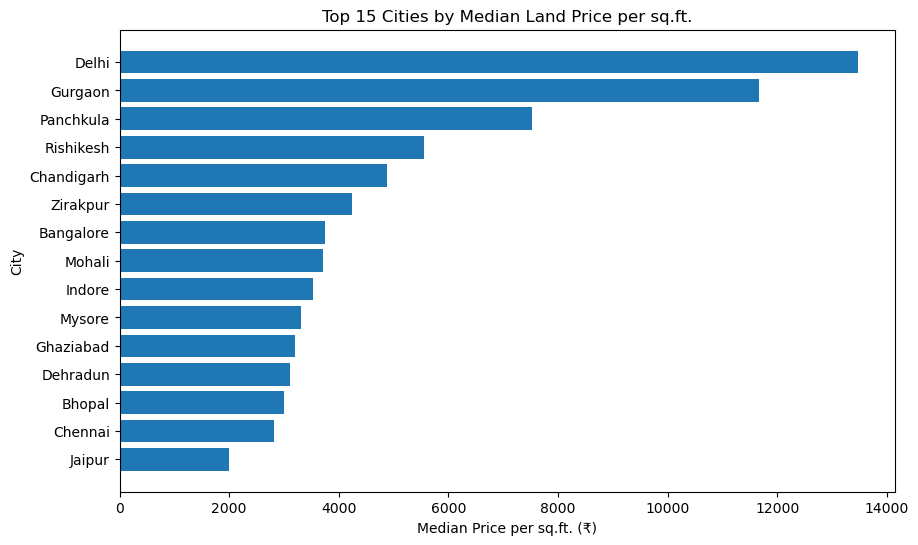

In [85]:
top_15 = city_analysis_100.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_15.index[::-1], top_15["median_price_per_area"][::-1])
plt.xlabel("Median Price per sq.ft. (₹)")
plt.ylabel("City")
plt.title("Top 15 Cities by Median Land Price per sq.ft.")
plt.show()

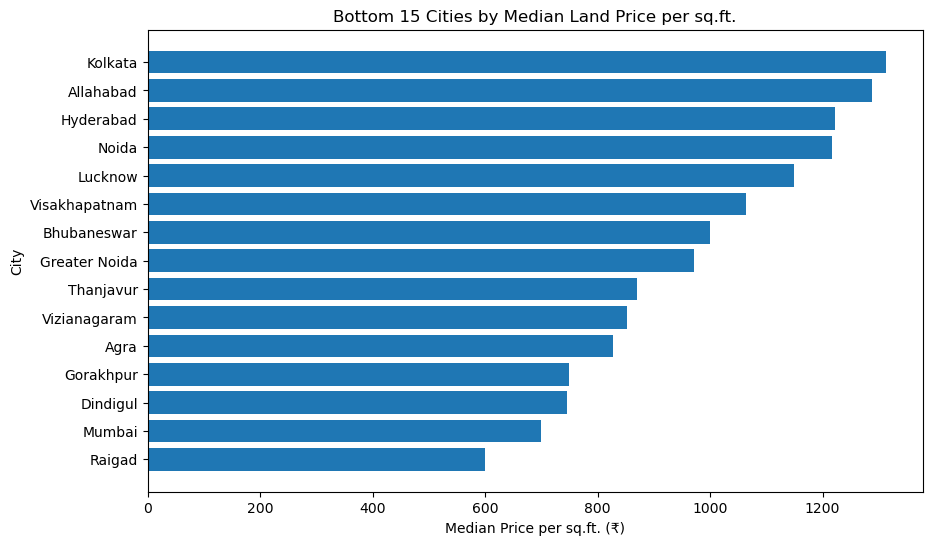

In [86]:
bottom_15 = city_analysis_100.tail(15)

plt.figure(figsize=(10, 6))
plt.barh(bottom_15.index[::-1], bottom_15["median_price_per_area"][::-1])
plt.xlabel("Median Price per sq.ft. (₹)")
plt.ylabel("City")
plt.title("Bottom 15 Cities by Median Land Price per sq.ft.")
plt.show()

In [87]:
final_df["area_category"] = pd.cut(
    final_df["Area"],
    bins=[0, 500, 1000, 1500, 2500, 5000, float("inf")],
    labels=["<500", "500-1000", "1000-1500", "1500-2500", "2500-5000", "5000+"]
)

In [88]:
area_analysis = (
    final_df.groupby("area_category", observed=True)["price_per_area"]
    .median()
)

area_analysis

area_category
<500         2122.0
500-1000     1793.0
1000-1500    1889.0
1500-2500    1728.0
2500-5000    3000.0
5000+        1666.0
Name: price_per_area, dtype: float64

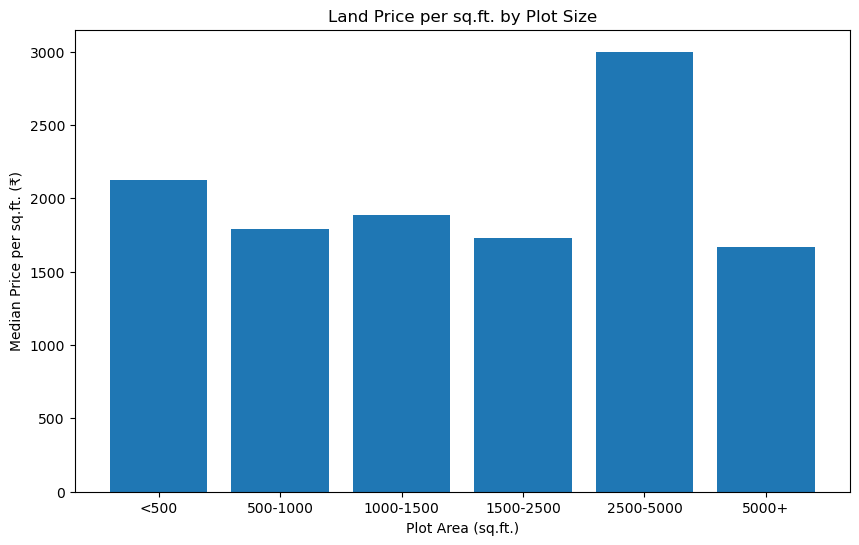

In [89]:
plt.figure(figsize=(10, 6))

plt.bar(
    area_analysis.index.astype(str),
    area_analysis.values
)

plt.xlabel("Plot Area (sq.ft.)")
plt.ylabel("Median Price per sq.ft. (₹)")
plt.title("Land Price per sq.ft. by Plot Size")

plt.show()

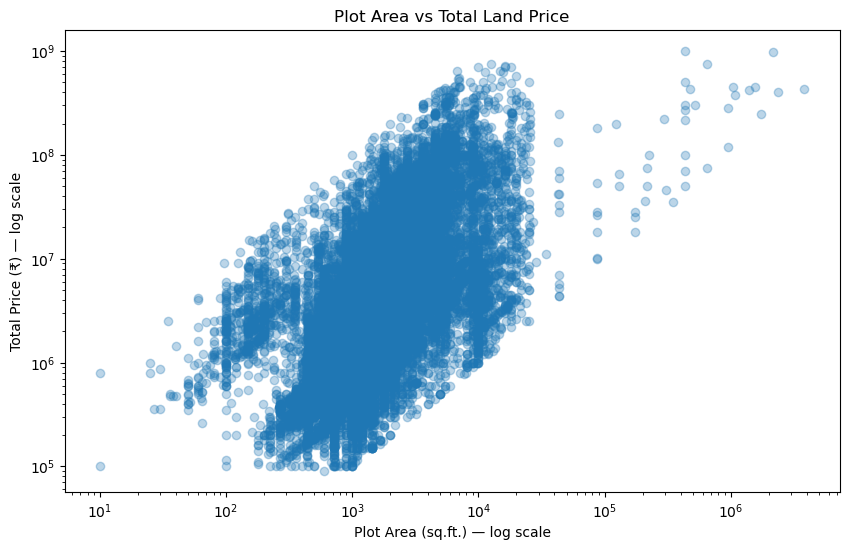

In [90]:
plt.figure(figsize=(10, 6))

plt.scatter(
    final_df["Area"],
    final_df["price_inr"],
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Plot Area (sq.ft.) — log scale")
plt.ylabel("Total Price (₹) — log scale")
plt.title("Plot Area vs Total Land Price")

plt.show()

In [91]:
final_df[["Area", "price_inr"]].corr()

,Area,price_inr
Area,1.000000,0.271954
price_inr,0.271954,1.000000


In [92]:
final_df[["Area", "price_inr"]].corr(method="spearman")

,Area,price_inr
Area,1.000000,0.556553
price_inr,0.556553,1.000000


In [93]:
region_analysis = (
    final_df.groupby("region")
    .agg(
        listings=("Area", "size"),
        median_price=("price_inr", "median"),
        median_area=("Area", "median"),
        median_price_per_area=("price_per_area", "median")
    )
    .sort_values("median_price_per_area", ascending=False)
)

region_analysis

,listings,median_price,median_area,median_price_per_area
region,,,,
North,15036,2700000.0,1242.0,2069.5
Northeast,98,9076500.0,4640.0,2041.5
South,25744,2900000.0,1503.0,1943.5
Central,2228,2200000.0,1200.0,1737.0
West,1514,2250000.0,1500.5,1250.5
East,2260,1820000.0,1500.0,1158.0


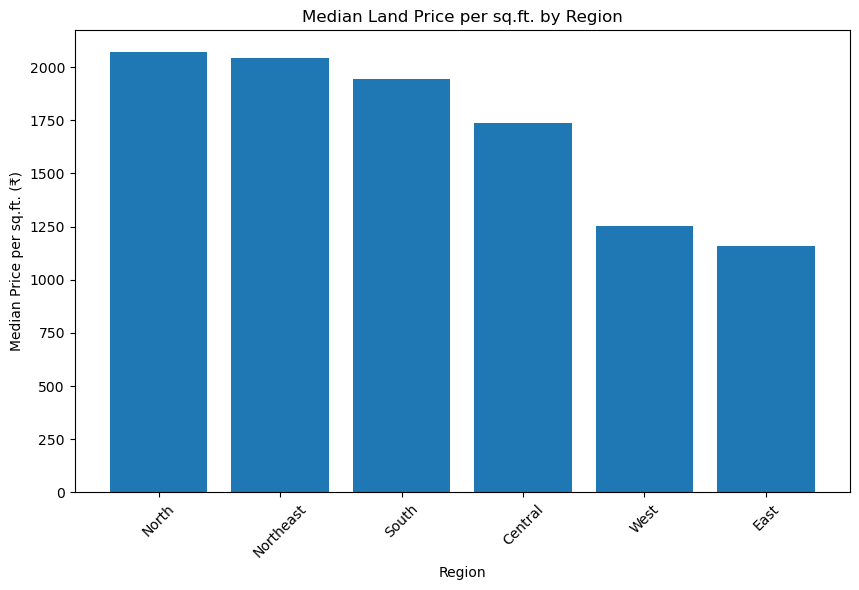

In [94]:
plt.figure(figsize=(10, 6))

plt.bar(
    region_analysis.index,
    region_analysis["median_price_per_area"]
)

plt.xlabel("Region")
plt.ylabel("Median Price per sq.ft. (₹)")
plt.title("Median Land Price per sq.ft. by Region")

plt.xticks(rotation=45)

plt.show()

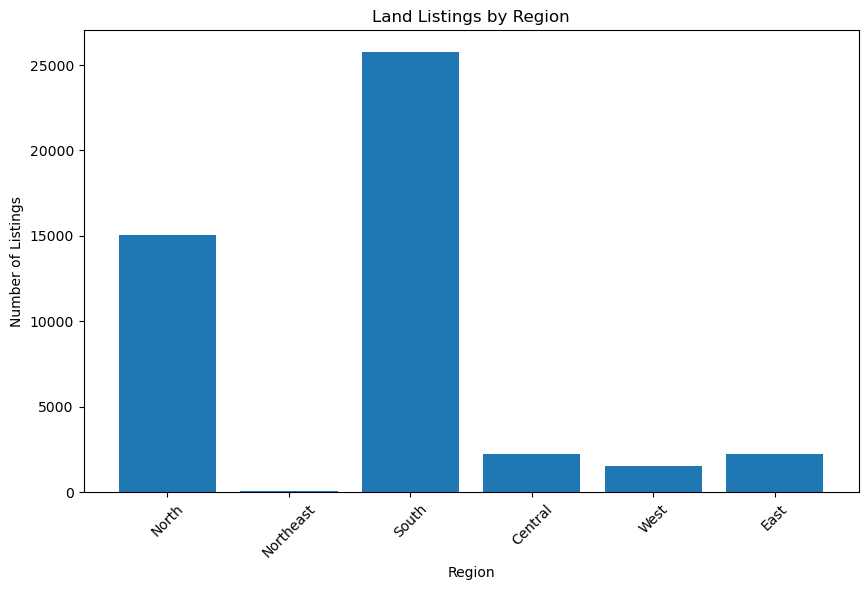

In [95]:
plt.figure(figsize=(10, 6))

plt.bar(
    region_analysis.index,
    region_analysis["listings"]
)

plt.xlabel("Region")
plt.ylabel("Number of Listings")
plt.title("Land Listings by Region")

plt.xticks(rotation=45)

plt.show()

In [96]:
Q1 = final_df[["Area", "price_inr", "price_per_area"]].quantile(0.25)
Q3 = final_df[["Area", "price_inr", "price_per_area"]].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_bounds = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower_Bound": lower_bound,
    "Upper_Bound": upper_bound
})

outlier_bounds

,Q1,Q3,IQR,Lower_Bound,Upper_Bound
Area,1000.0,2153.0,1153.0,-729.5,3882.5
price_inr,1426000.0,6000000.0,4574000.0,-5435000.0,12861000.0
price_per_area,1000.0,3888.0,2888.0,-3332.0,8220.0


In [97]:
outlier_counts = {}

for col in ["Area", "price_inr", "price_per_area"]:
    outlier_counts[col] = (
        (final_df[col] < lower_bound[col]) |
        (final_df[col] > upper_bound[col])
    ).sum()

outlier_counts

{'Area': np.int64(4499),
 'price_inr': np.int64(6245),
 'price_per_area': np.int64(4703)}

In [98]:
outlier_percentage = {
    col: (outlier_counts[col] / len(final_df)) * 100
    for col in outlier_counts
}

outlier_percentage

{'Area': np.float64(9.59684300341297),
 'price_inr': np.float64(13.321245733788395),
 'price_per_area': np.float64(10.031996587030717)}

In [99]:
final_df.nlargest(20, "Area")[["Area", "price_inr", "price_per_area", "city", "state"]]

,Area,price_inr,price_per_area,city,state
84747,3833280,435600000.0,113.0,Kottayam,Kerala
113674,2352240,400000000.0,170.0,Hyderabad,Telangana
70313,2178000,990000000.0,454.0,Bangalore,Karnataka
113447,1745201,250000000.0,143.0,Hyderabad,Telangana
138856,1570681,450000000.0,286.0,Moradabad,Uttar Pradesh
199324,1393920,420000000.0,301.0,Chennai,Tamil Nadu
99677,1089000,375000000.0,344.0,Dera Bassi,Punjab
147987,1045440,450000000.0,430.0,Mathura,Uttar Pradesh
106816,959860,280500000.0,292.0,Jaipur,Rajasthan
38918,958320,120000000.0,125.0,Gurgaon,Haryana


In [100]:
final_df.nlargest(20, "price_inr")[["Area", "price_inr", "price_per_area", "city", "state"]]

,Area,price_inr,price_per_area,city,state
18729,435600,999900000.0,2295.0,Delhi,Delhi
70313,2178000,990000000.0,454.0,Bangalore,Karnataka
28400,12672,750000000.0,59185.0,Delhi,Delhi
34784,653400,750000000.0,1147.0,Gurgaon,Haryana
120073,16200,720000000.0,44444.0,Hyderabad,Telangana
116814,18000,710000000.0,39444.0,Hyderabad,Telangana
87917,10000,700000000.0,70000.0,Indore,Madhya Pradesh
120065,16200,700000000.0,43209.0,Hyderabad,Telangana
33893,6804,641200000.0,94247.0,Delhi,Delhi
120064,14850,640000000.0,43097.0,Hyderabad,Telangana


In [101]:
final_df.nlargest(20, "price_per_area")[["Area", "price_inr", "price_per_area", "city", "state"]]

,Area,price_inr,price_per_area,city,state
11688,1000,100000000.0,100000.0,Delhi,Delhi
34534,500,50000000.0,100000.0,Gurgaon,Haryana
58885,1500,150000000.0,100000.0,Mysore,Karnataka
33968,2010,200400000.0,99707.0,Delhi,Delhi
157243,153,15000000.0,98039.0,Noida,Uttar Pradesh
33939,1440,140000000.0,97222.0,Delhi,Delhi
58245,96,9200000.0,95833.0,Faridabad,Haryana
33912,2420,230000000.0,95041.0,Delhi,Delhi
33893,6804,641200000.0,94247.0,Delhi,Delhi
157031,162,14800000.0,91412.0,Noida,Uttar Pradesh


## Outlier review
The IQR rule flags about 10% of rows, which is too many to remove. Manual checks found extreme areas (up to 3.8 million sq ft), very high prices (up to ₹99 crore) and several rows at exactly ₹100,000 per sq ft, which may be a platform cap. These rows look like real listings or unverified entries, not clear errors, so they are **kept**, and medians are used to limit their effect.

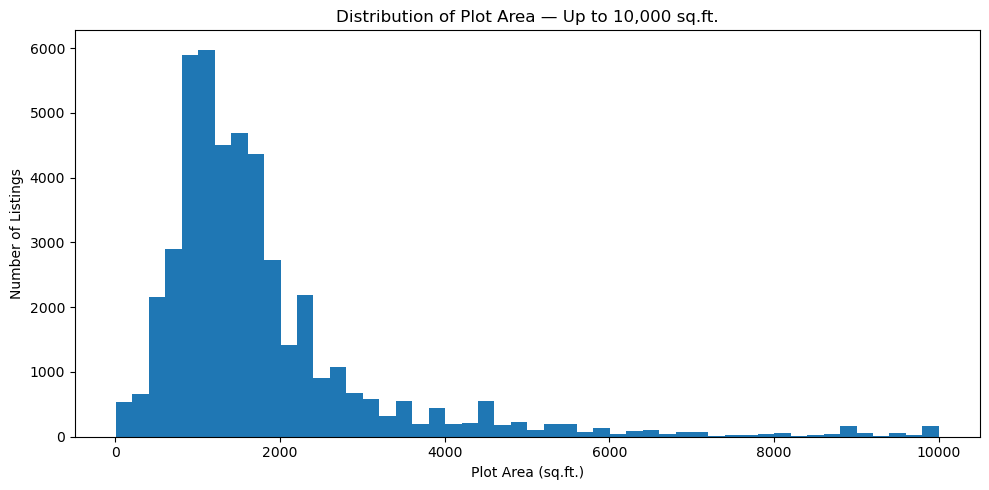

In [102]:
plt.figure(figsize=(10, 5))

plt.hist(
    final_df["Area"][final_df["Area"] <= 10000],
    bins=50
)

plt.xlabel("Plot Area (sq.ft.)")
plt.ylabel("Number of Listings")
plt.title("Distribution of Plot Area — Up to 10,000 sq.ft.")

plt.tight_layout()
plt.show()

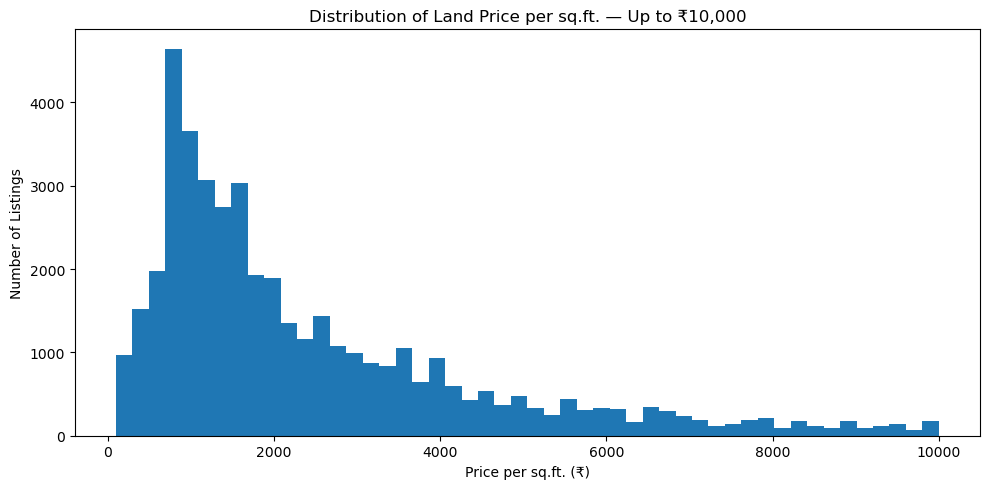

In [103]:
plt.figure(figsize=(10, 5))

plt.hist(
    final_df["price_per_area"][final_df["price_per_area"] <= 10000],
    bins=50
)

plt.xlabel("Price per sq.ft. (₹)")
plt.ylabel("Number of Listings")
plt.title("Distribution of Land Price per sq.ft. — Up to ₹10,000")

plt.tight_layout()
plt.show()

In [104]:
suspicious = final_df[
    (final_df["price_per_area"] > 50000) |
    (final_df["price_inr"] > 500000000) |
    (final_df["Area"] > 100000)
]

suspicious[
    ["Area", "price_inr", "price_per_area", "city", "state"]
].sort_values("price_per_area", ascending=False).head(30)

,Area,price_inr,price_per_area,city,state
11688,1000,100000000.0,100000.0,Delhi,Delhi
34534,500,50000000.0,100000.0,Gurgaon,Haryana
58885,1500,150000000.0,100000.0,Mysore,Karnataka
33968,2010,200400000.0,99707.0,Delhi,Delhi
157243,153,15000000.0,98039.0,Noida,Uttar Pradesh
33939,1440,140000000.0,97222.0,Delhi,Delhi
58245,96,9200000.0,95833.0,Faridabad,Haryana
33912,2420,230000000.0,95041.0,Delhi,Delhi
33893,6804,641200000.0,94247.0,Delhi,Delhi
157031,162,14800000.0,91412.0,Noida,Uttar Pradesh


In [105]:
print("Area <= 0:", (final_df["Area"] <= 0).sum())
print("Price <= 0:", (final_df["price_inr"] <= 0).sum())
print("Price per area <= 0:", (final_df["price_per_area"] <= 0).sum())

print("Missing Area:", final_df["Area"].isna().sum())
print("Missing Price:", final_df["price_inr"].isna().sum())
print("Missing Price per Area:", final_df["price_per_area"].isna().sum())

Area <= 0: 0
Price <= 0: 0
Price per area <= 0: 0
Missing Area: 0
Missing Price: 0
Missing Price per Area: 0


In [106]:
city_outliers = (
    final_df[final_df["price_per_area"] > 50000]
    .groupby("city")
    .agg(
        listings=("price_per_area", "size"),
        median_price_per_area=("price_per_area", "median"),
        max_price_per_area=("price_per_area", "max")
    )
    .sort_values("max_price_per_area", ascending=False)
)

city_outliers

,listings,median_price_per_area,max_price_per_area
city,,,
Delhi,109,59185.0,100000.0
Gurgaon,16,68333.0,100000.0
Mysore,1,100000.0,100000.0
Noida,2,94725.5,98039.0
Faridabad,2,74583.0,95833.0
Jaipur,6,58333.0,88888.0
Hyderabad,13,72916.0,86816.0
Chennai,3,68376.0,83333.0
Rishikesh,14,61000.0,80714.0


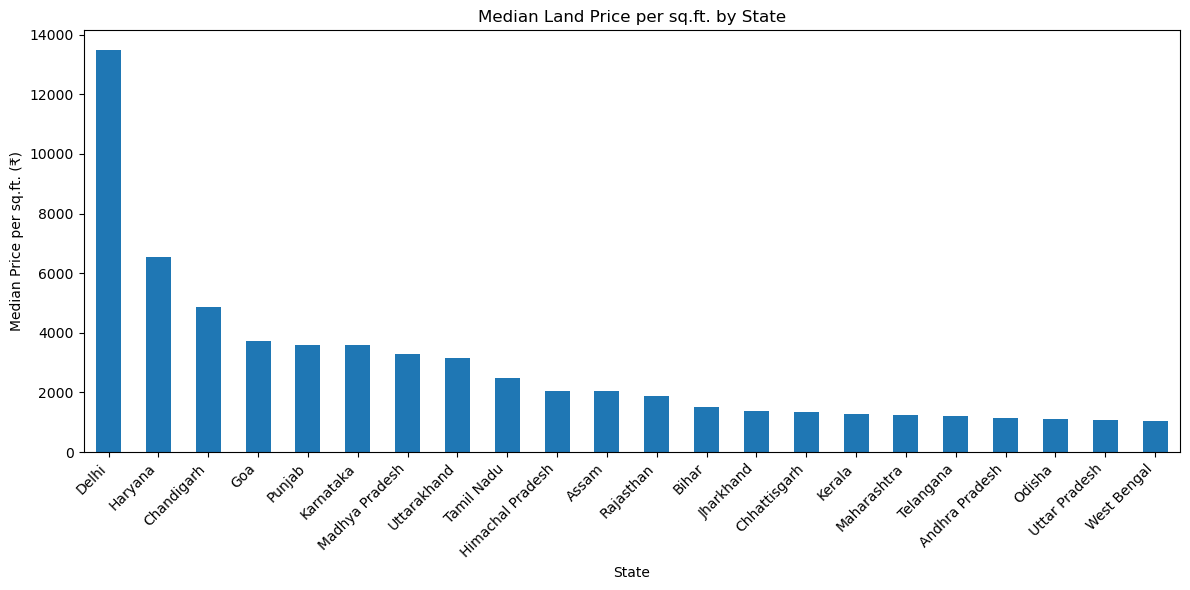

In [107]:
state_price = (
    final_df.groupby("state")["price_per_area"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
state_price.plot(kind="bar")

plt.title("Median Land Price per sq.ft. by State")
plt.xlabel("State")
plt.ylabel("Median Price per sq.ft. (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

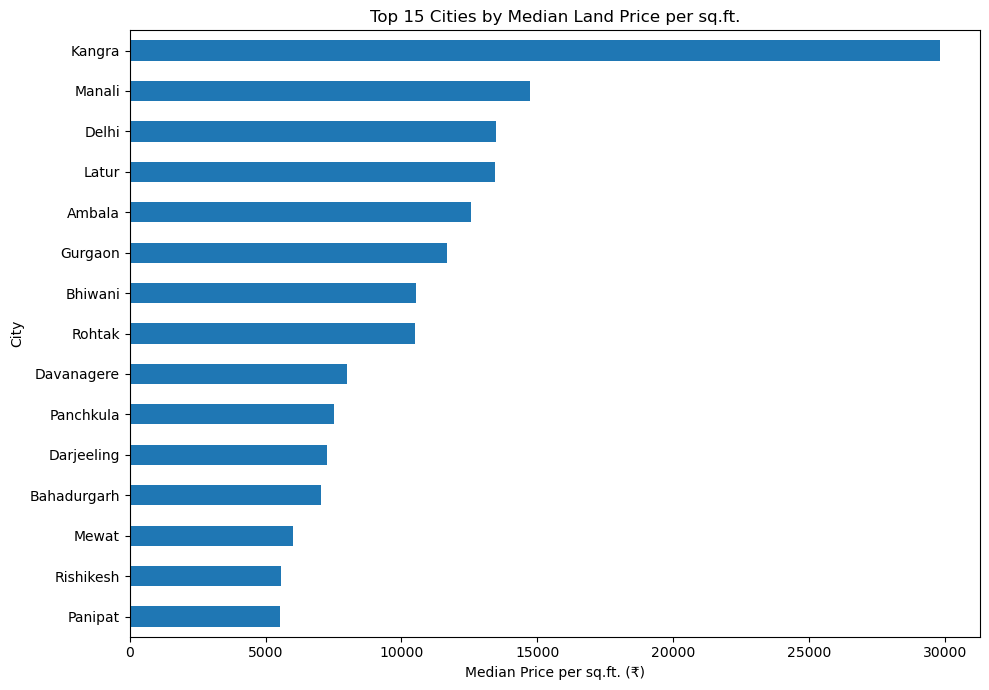

In [108]:
city_price = (
    final_df.groupby("city")["price_per_area"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 7))
city_price.sort_values().plot(kind="barh")

plt.title("Top 15 Cities by Median Land Price per sq.ft.")
plt.xlabel("Median Price per sq.ft. (₹)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

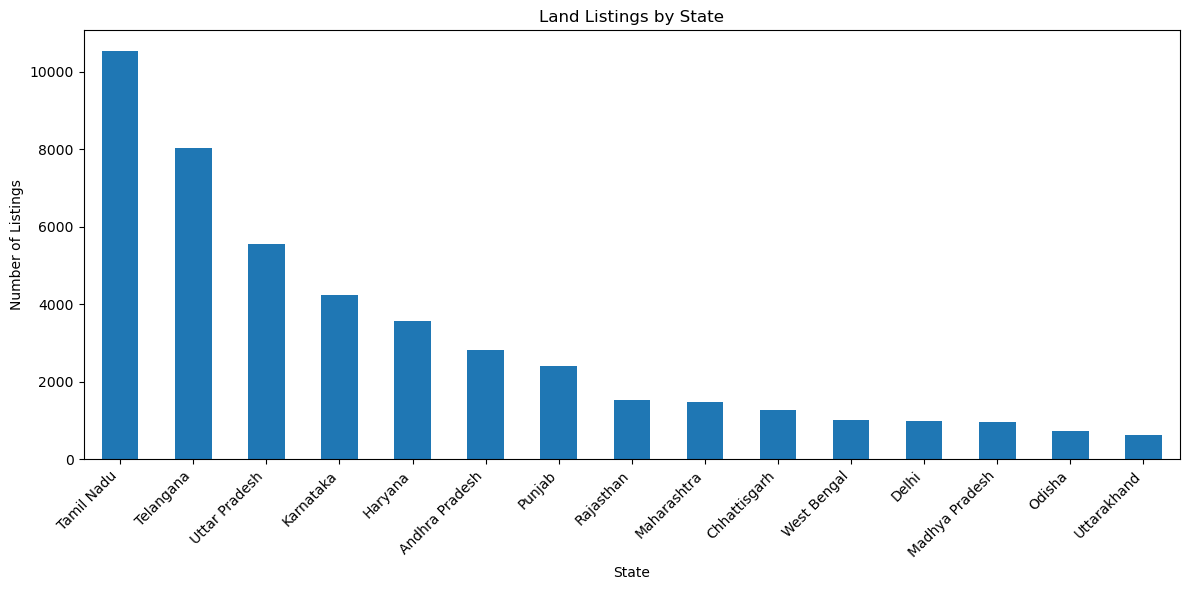

In [109]:
state_listings = (
    final_df["state"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))
state_listings.plot(kind="bar")

plt.title("Land Listings by State")
plt.xlabel("State")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

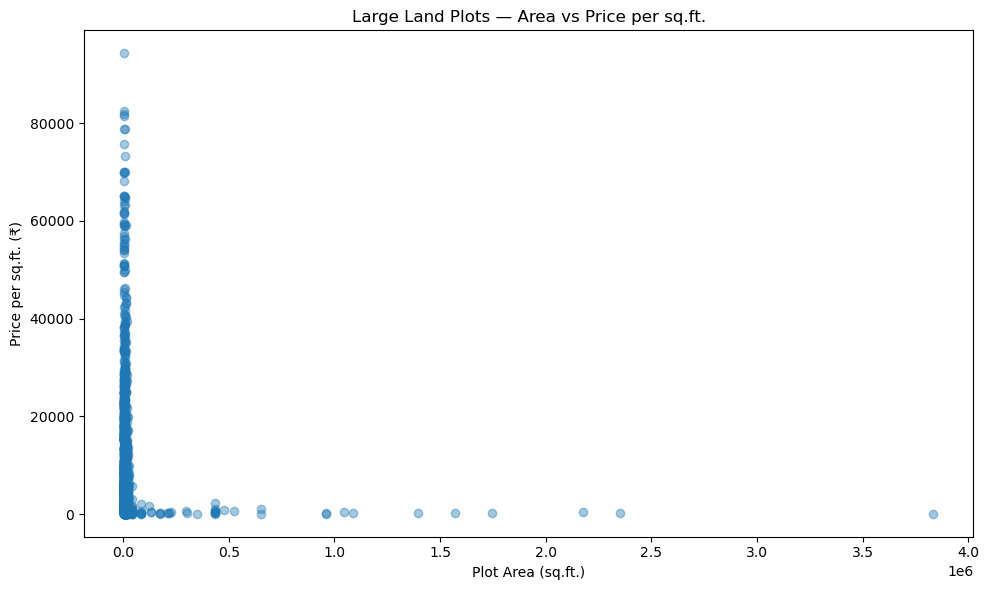

In [110]:
large_plots = final_df[final_df["Area"] > 5000]

plt.figure(figsize=(10, 6))

plt.scatter(
    large_plots["Area"],
    large_plots["price_per_area"],
    alpha=0.4
)

plt.title("Large Land Plots — Area vs Price per sq.ft.")
plt.xlabel("Plot Area (sq.ft.)")
plt.ylabel("Price per sq.ft. (₹)")

plt.tight_layout()
plt.show()

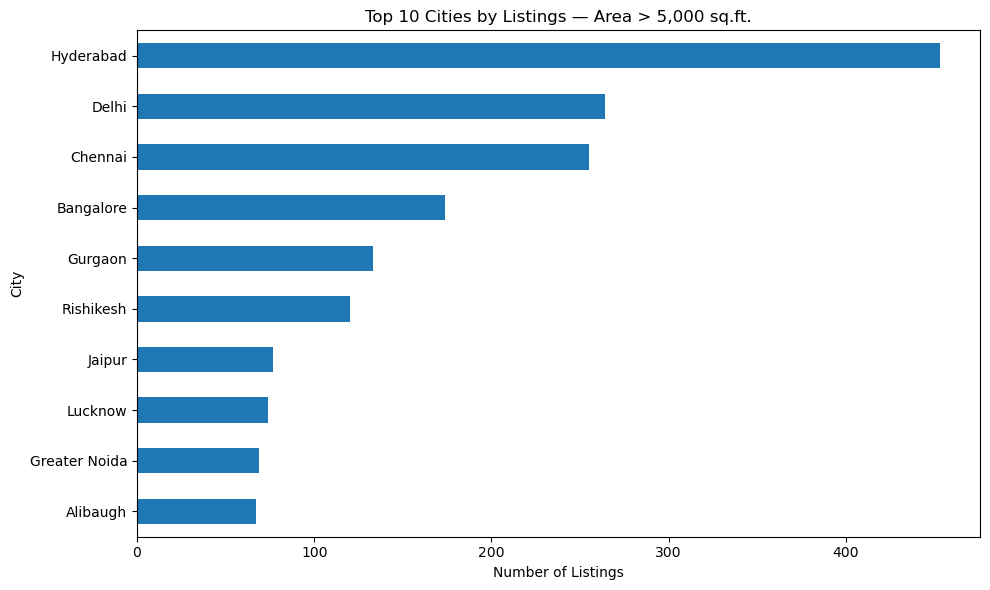

In [111]:

large_plots = final_df[final_df["Area"] > 5000]

# Count listings by city and select top 10
top_10_cities = (
    large_plots["city"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_10_cities.plot(kind="barh")

plt.title("Top 10 Cities by Listings — Area > 5,000 sq.ft.")
plt.xlabel("Number of Listings")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [112]:
large_plots = final_df[final_df["Area"] > 5000].copy()

In [113]:
city_opportunity = (
    large_plots.groupby("city")
    .agg(
        listings=("city", "size"),
        median_area=("Area", "median"),
        median_price_per_area=("price_per_area", "median"),
        median_price=("price_inr", "median")
    )
    .sort_values("listings", ascending=False)
)

city_opportunity.head(20)

,listings,median_area,median_price_per_area,median_price
city,,,,
Hyderabad,453,7465.0,1000.0,8763000.0
Delhi,264,6226.0,20222.0,128200000.0
Chennai,255,9641.0,1500.0,12000000.0
Bangalore,174,7200.0,5471.0,37500000.0
Gurgaon,133,8370.0,8888.0,70000000.0
Rishikesh,120,12600.0,4888.5,53000000.0
Jaipur,77,9900.0,4666.0,50000000.0
Lucknow,74,10000.0,599.0,5990000.0
Greater Noida,69,7100.0,823.0,5544000.0


In [114]:
city_opportunity_20 = city_opportunity[
    city_opportunity["listings"] >= 20
].copy()

In [115]:
city_opportunity_20.sort_values(
    "median_price_per_area"
).head(15)

,listings,median_area,median_price_per_area,median_price
city,,,,
Trichy,21,10000.0,358.0,3850000.0
Noida,63,10000.0,379.0,3750000.0
Mumbai,20,6000.0,527.5,3550000.0
Lucknow,74,10000.0,599.0,5990000.0
Bhubaneswar,24,8000.0,719.0,8000000.0
Guntur,30,9075.5,721.5,6183500.0
Raigad,32,6030.0,800.0,4740000.0
Raipur,44,10000.0,805.0,7315000.0
Greater Noida,69,7100.0,823.0,5544000.0


In [116]:
candidate_cities = city_opportunity_20[
    city_opportunity_20["listings"] >= 40
].sort_values("median_price_per_area")

candidate_cities

,listings,median_area,median_price_per_area,median_price
city,,,,
Noida,63,10000.0,379.0,3750000.0
Lucknow,74,10000.0,599.0,5990000.0
Raipur,44,10000.0,805.0,7315000.0
Greater Noida,69,7100.0,823.0,5544000.0
Kolkata,67,10800.0,833.0,9244000.0
Alibaugh,67,9000.0,929.0,8425000.0
Hyderabad,453,7465.0,1000.0,8763000.0
Coimbatore,51,9583.0,1262.0,12600000.0
Chennai,255,9641.0,1500.0,12000000.0


## Key findings
- Median price: about ₹1,855 per sq ft; median plot about 1,450 sq ft.
- Delhi is the most expensive state; Gurgaon, Panchkula and Rishikesh lead among cities with 100+ listings.
- North has the highest regional median and East the lowest.
- Area and total price are positively related (Spearman 0.56), but price per sq ft does not fall steadily with size.

## Limitations
- Asking prices, not sale prices.
- Uneven coverage: Chennai and Hyderabad make up about a third of listings, and some states are missing.
- Outliers and 36 mismatched price rows are kept.